# Expense to account classifier

Peakflo take-home. Goal: predict `accountName` for each bill line item, with at least 85% accuracy
(their internal model reaches 92%).

The plan is deliberately simple:

1. Clean the data and pull a date out of each record.
2. A memory lookup: if this vendor has billed this exact line before, reuse the account.
3. A single logistic regression on text, vendor, month and amount for everything else.
4. Evaluate with cross-validation grouped by bill, and again with a time split.

Every random seed is fixed, so the numbers below are reproducible.

In [1]:
import json
import re
import warnings
from collections import Counter, defaultdict
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 60)

## 1. Load and clean

Two things are not obvious from the field list:

* `_id` is the bill, not the line. 4,894 lines belong to 3,181 bills. We need that for validation.
* `_id` is a Mongo ObjectId, and its first 8 hex characters are a creation timestamp.
  That gives every row a date, which turns out to matter (see the renamed accounts below).

In [2]:
with open("accounts-bills.json") as f:
    raw = json.load(f)

df = pd.DataFrame(raw)
df["bill_id"] = df["_id"].apply(lambda x: x["$oid"])
df["date"] = df["bill_id"].apply(lambda s: datetime.fromtimestamp(int(s[:8], 16), tz=timezone.utc))
df["quarter"] = df["date"].dt.year.astype(str) + "Q" + df["date"].dt.quarter.astype(str)
df["itemDescription"] = df["itemDescription"].fillna("")
df["itemName"] = df["itemName"].fillna("")
df = df.drop(columns=["_id"])

print(f"{len(df):,} lines, {df['bill_id'].nunique():,} bills, {df['vendorId'].nunique()} vendors, "
      f"{df['accountName'].nunique()} account names")
print("date range:", df["date"].min().date(), "to", df["date"].max().date())
df.head(3)

4,894 lines, 3,181 bills, 337 vendors, 103 account names
date range: 2024-04-03 to 2026-02-10


,vendorId,itemName,itemDescription,accountId,accountName,itemTotalAmount,bill_id,date,quarter
0,6m656Er7lbi8RYz2ny1J,1225 Business 2Gbps - monthly subscription fee,1225 Business 2Gbps - monthly subscription fee,88AW5nmkLvMe1GthZ6FL,619206 Telephone & Internet,888.00,69606546de1e297ec29890f2,2026-01-09 02:17:42+00:00,2026Q1
1,VtxikZ7HI6Jwqueemjch,1225-0227 media monitoring,1225-0227 media monitoring,sWG9pai5DiLXaKs6s86G,134004 Prepaid Subscription,17765.00,695b5304d09b4ceb96e5288e,2026-01-05 05:58:28+00:00,2026Q1
2,jdmr9pJ0WHqso4Wh3hCa,0226 Branch,0226 Branch,C0SB5vR0gCikdKjmT8Ep,611202 Online Subscription/Tool,7083.34,69800f97e85d532c0db71c7e,2026-02-02 02:44:39+00:00,2026Q1


In [3]:
def clean_text(name, desc):
    """Join name and description (only when they differ) and strip the month prefix.

    Most item names start with a period code such as '1225' or '0925-1125'.
    That is bookkeeping noise for the text model, so we remove it. We keep the date
    as a separate numeric feature instead.
    """
    text = name if name.strip() == desc.strip() else f"{name} {desc}"
    text = re.sub(r"^\s*\d{4}(\s*-\s*\d{4})?\s*[-:]?\s*", "", text)
    return text.lower().strip()


def months_covered(name):
    """A prefix like '0126-1226' means the line covers Jan to Dec 2026. Return the number of months.

    Lines that cover many months are usually prepaid, lines that cover one month are usually
    plain expenses. 0 means no range was given.
    """
    m = re.match(r"^\s*(\d{2})(\d{2})\s*-\s*(\d{2})(\d{2})", name)
    if not m:
        return 0
    start = int(m.group(2)) * 12 + int(m.group(1))
    end = int(m.group(4)) * 12 + int(m.group(3))
    return min(max(end - start + 1, 0), 36)


def bucket_months(n):
    return "none" if n == 0 else "1" if n == 1 else "2-6" if n <= 6 else "7-12" if n <= 12 else "13+"


df["text"] = [clean_text(n, d) for n, d in zip(df["itemName"], df["itemDescription"])]
df["months_bin"] = df["itemName"].map(months_covered).map(bucket_months)
df["lines_in_bill"] = df.groupby("bill_id")["text"].transform("size").map(lambda n: "1" if n == 1 else "2-3" if n <= 3 else "4+")
has_prefix = df["itemName"].str.match(r"^\s*\d{4}")
print(f"rows with a period prefix: {has_prefix.sum():,}   without: {(~has_prefix).sum()}")
print(f"rows with an empty description: {(df['itemDescription'] == '').sum()}")
df[["itemName", "text", "months_bin", "lines_in_bill"]].sample(5, random_state=SEED)

rows with a period prefix: 4,362   without: 532
rows with an empty description: 31


,itemName,text,months_bin,lines_in_bill
144,0126 Zoom Workplace Pro Monthly,zoom workplace pro monthly,none,2-3
79,1225 - Monthly Premium Plan Contract,monthly premium plan contract 12-month custom premium p...,none,4+
4627,0424 INTERNATIONAL REGISTRATION NO. 1786082 DESIGNATING ...,international registration no. 1786082 designating malay...,none,1
3832,0724 TW Goods - Demand - Facebook,tw goods - demand - facebook,none,2-3
4581,0424-0624 Darwinbox Subscription Fee (Carousell),darwinbox subscription fee (carousell),2-6,4+


## 2. What the data looks like

Top 10 accounts:
accountName
611202 Online Subscription/Tool                1179
132098 IC Clearing account                      706
619203 Supplies/Expenses                        225
134001 Prepaid Operating Expense                193
614123 Employee On Record                       175
132098 IC Clearing account - Paid on Behalf     131
617103 Subcontractors/Outsource                 126
617205 Consultancy Expense                      121
619201 Equipment Expense                        114
619209 Others                                    99

The top class is 24% of all rows.
34 of 103 accounts have fewer than 5 rows (68 rows in total). 16 accounts appear once.


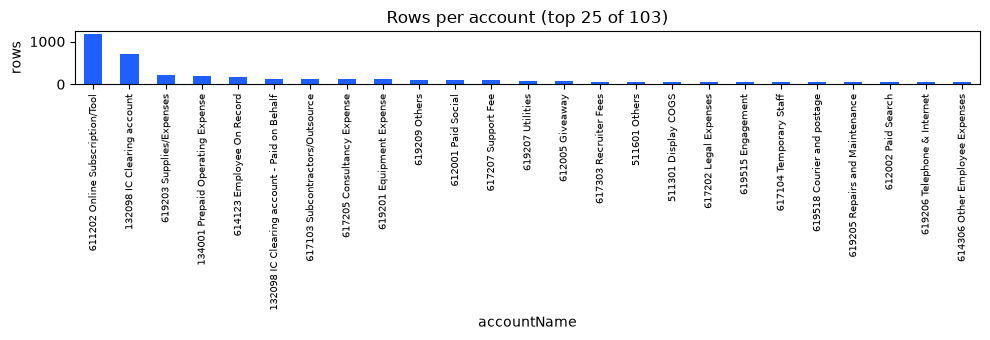

In [4]:
counts = df["accountName"].value_counts()
print("Top 10 accounts:")
print(counts.head(10).to_string())
print(f"\nThe top class is {counts.iloc[0] / len(df):.0%} of all rows.")
print(f"{(counts < 5).sum()} of {len(counts)} accounts have fewer than 5 rows "
      f"({counts[counts < 5].sum()} rows in total). {(counts == 1).sum()} accounts appear once.")

fig, ax = plt.subplots(figsize=(10, 3.5))
counts.head(25).plot.bar(ax=ax, color="#1f5eff")
ax.set_title("Rows per account (top 25 of 103)")
ax.set_ylabel("rows")
ax.tick_params(axis="x", labelsize=7)
plt.tight_layout()
plt.savefig("figures/class_counts.png", dpi=130)
plt.show()

**Vendor is a strong but incomplete signal.** Guessing each vendor's most common account gets ~74%
on the training data itself, so the text has to carry the rest.

In [5]:
vendor_accounts = df.groupby("vendorId")["accountName"].agg(["nunique", "size"])
print(f"{(vendor_accounts['nunique'] == 1).sum()} of {len(vendor_accounts)} vendors always map to one account.")
vendor_majority_acc = df.groupby("vendorId")["accountName"].agg(lambda s: s.value_counts().iloc[0]).sum() / len(df)
print(f"Vendor-majority guess, in sample: {vendor_majority_acc:.1%}")
print("\nVendors spread over the most accounts:")
print(vendor_accounts.sort_values("nunique", ascending=False).head(5).to_string())

211 of 337 vendors always map to one account.
Vendor-majority guess, in sample: 73.9%

Vendors spread over the most accounts:
                      nunique  size
vendorId                           
lL1pcuEf3q6ufBVg2R75       19   380
A17M26ij1P8uGEnRFtP0        9   250
Sdo77dqAgGk4K3SF5iet        7    44
bfN8jYCNYKQFk7yN2vvN        7    77
VGpMltxLedu3HLJ4VwZ9        6    77


**Six account IDs carry two names each.** Plotting them over time shows these are renames:
the old name stops and the new one starts. So the date is a real signal for the target.

                                                                                       min                       max  size
accountId            accountName                                                                                          
6yL6YRA4Rkj2gUD4RAO0 230051 Lease payable                        2024-04-11 06:24:26+00:00 2024-11-08 13:04:40+00:00    15
                     232101 Lease payable                        2024-12-11 07:54:44+00:00 2026-02-03 06:35:43+00:00    29
AS7kZeVZgNNPi7UQOSKD 222003 Customer Prepayment                  2024-09-18 10:17:30+00:00 2024-09-24 10:57:43+00:00     2
                     231101 Customer Prepayment                  2024-12-17 14:06:23+00:00 2026-01-14 10:42:53+00:00    16
lXfE1brSF0STqngL58cZ 612039 Marketing Research                   2025-01-23 03:02:25+00:00 2025-01-23 03:02:25+00:00     1
                     617213 Marketing Research                   2024-11-04 02:45:38+00:00 2024-11-04 02:45:38+00:00     1
riKWPz2LlaISic7O

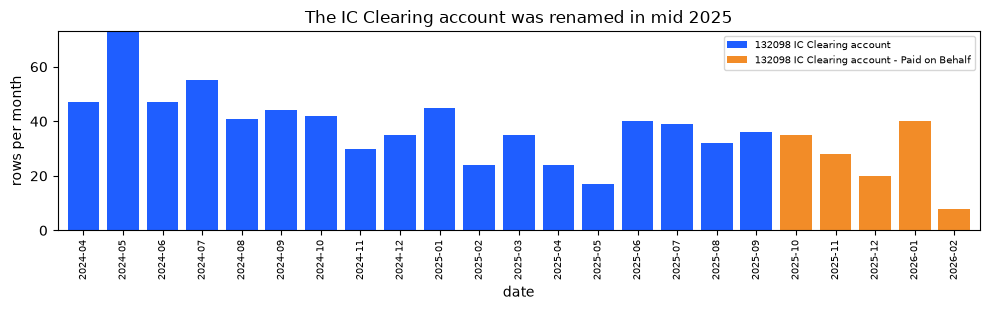

In [6]:
two_names = df.groupby("accountId")["accountName"].nunique()
renamed_ids = two_names[two_names > 1].index
pairs = df[df["accountId"].isin(renamed_ids)]
print(pairs.groupby(["accountId", "accountName"])["date"].agg(["min", "max", "size"]).to_string())

fig, ax = plt.subplots(figsize=(10, 3.2))
ic = df[df["accountName"].str.startswith("132098")]
monthly = ic.groupby([ic["date"].dt.to_period("M"), "accountName"]).size().unstack(fill_value=0)
monthly.plot.bar(stacked=True, ax=ax, width=0.8, color=["#1f5eff", "#f28c28"])
ax.set_title("The IC Clearing account was renamed in mid 2025")
ax.set_ylabel("rows per month")
ax.tick_params(axis="x", labelsize=7)
ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig("figures/renamed_account_timeline.png", dpi=130)
plt.show()

**Amounts** are mostly small SGD values, but 7 rows are above one million (a laptop at 108 million is
clearly another currency) and 19 are negative (credit notes). We only use the sign and rough size.

In [7]:
amt = df["itemTotalAmount"]
print(f"negative: {(amt < 0).sum()}   above 1M: {(amt > 1e6).sum()}   median: {amt.median():,.0f}   "
      f"90th pct: {amt.quantile(0.9):,.0f}")
print(f"\nitemName equals itemDescription in {(df['itemName'] == df['itemDescription']).mean():.0%} of rows.")
print(f"Bills with lines in more than one account: {(df.groupby('bill_id')['accountName'].nunique() > 1).sum()}")

negative: 19   above 1M: 7   median: 845   90th pct: 9,708

itemName equals itemDescription in 83% of rows.
Bills with lines in more than one account: 388


**Finance data repeats.** The same vendor bills the same line month after month. How often does a
(vendor, cleaned text) pair recur, and when it does, how consistent is the account? This decides
how much a plain lookup can do before any model is needed.

In [8]:
pair_counts = defaultdict(Counter)
for v, t, y in zip(df["vendorId"], df["text"], df["accountName"]):
    pair_counts[(v, t)][y] += 1

seen_elsewhere = unanimous = unanimous_correct = 0
for v, t, y in zip(df["vendorId"], df["text"], df["accountName"]):
    others = pair_counts[(v, t)].copy()
    others[y] -= 1
    others = +others  # drop the row itself
    if sum(others.values()) > 0:
        seen_elsewhere += 1
        if len(others) == 1:
            unanimous += 1
            unanimous_correct += next(iter(others)) == y
print(f"rows whose (vendor, text) pair appears in other rows: {seen_elsewhere / len(df):.1%}")
print(f"rows where those other rows agree on one account:     {unanimous / len(df):.1%}")
print(f"accuracy of that unanimous lookup (leave one out):     {unanimous_correct / unanimous:.1%}")

rows whose (vendor, text) pair appears in other rows: 58.0%
rows where those other rows agree on one account:     51.4%
accuracy of that unanimous lookup (leave one out):     98.5%


## 3. The model

### 3a. Memory lookup

Finance data repeats. The same vendor bills the same line every month. If we have seen this exact
(vendor, cleaned text) pair before and it always got the same account, reuse it. This is precise
and easy to explain to a reviewer: "coded like the previous bill".

In [9]:
class Memory:
    def fit(self, vendors, texts, labels):
        self.table = defaultdict(Counter)
        for v, t, y in zip(vendors, texts, labels):
            self.table[(v, t)][y] += 1
        return self

    def predict(self, vendors, texts):
        """Return the remembered account, or None when unseen or the history disagrees."""
        out = []
        for v, t in zip(vendors, texts):
            seen = self.table.get((v, t))
            out.append(next(iter(seen)) if seen and len(seen) == 1 else None)
        return np.array(out, dtype=object)

### 3b. Features and logistic regression

* Word TF-IDF (1 to 2 word phrases) picks up keywords like "subscription" or "training".
* Character TF-IDF (2 to 5 letters) survives typos, SKUs and brand fragments.
* Vendor as one-hot columns.
* Quarter as one-hot columns, so the model can learn that an account changed name at some point.
  A quarter it has never seen simply gets no columns, which is a safe fallback.
* Amount as coarse bins (sign and order of magnitude), never the raw number.
* How many months the line covers (from the '0126-1226' style prefix) and how many lines the bill has.

Class weights are the inverse square root of class frequency. Full balancing over-predicts the
tiny classes and hurts overall accuracy; no weighting ignores them. Square root is the middle ground.

In [10]:
def amount_bin(x):
    if x < 0:
        return "negative"
    if x == 0:
        return "zero"
    return f"1e{int(np.floor(np.log10(x)))}"


class Model:
    def __init__(self, categoricals, C=5.0):
        self.categoricals = list(categoricals)
        self.C = C

    def _build(self, d, fit):
        parts = []
        if fit:
            self.word = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
            self.char = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)
            self.onehot = OneHotEncoder(handle_unknown="ignore")
            parts.append(self.word.fit_transform(d["text"]))
            parts.append(self.char.fit_transform(d["text"]))
            parts.append(self.onehot.fit_transform(d[self.categoricals]))
        else:
            parts.append(self.word.transform(d["text"]))
            parts.append(self.char.transform(d["text"]))
            parts.append(self.onehot.transform(d[self.categoricals]))
        return sparse.hstack(parts).tocsr()

    def fit(self, d):
        d = d.assign(amount_bin=d["itemTotalAmount"].map(amount_bin))
        X = self._build(d, fit=True)
        freq = d["accountName"].value_counts()
        weights = {k: float(np.sqrt(freq.max() / v)) for k, v in freq.items()}
        self.clf = LogisticRegression(C=self.C, max_iter=3000, class_weight=weights, random_state=SEED)
        self.clf.fit(X, d["accountName"])
        self.classes_ = self.clf.classes_
        return self

    def predict_proba(self, d):
        d = d.assign(amount_bin=d["itemTotalAmount"].map(amount_bin))
        return self.clf.predict_proba(self._build(d, fit=False))

### 3c. Putting the two together

`predict_split` trains on one part of the data and predicts the other. It returns the predicted
account, a confidence, the top 3 suggestions, and whether the memory answered.
Memory hits get a fixed confidence equal to the memory's measured precision on the training part.

In [11]:
def memory_precision(train):
    """Leave-one-out precision of the memory on the training rows."""
    table = defaultdict(Counter)
    for v, t, y in zip(train["vendorId"], train["text"], train["accountName"]):
        table[(v, t)][y] += 1
    hits = correct = 0
    for v, t, y in zip(train["vendorId"], train["text"], train["accountName"]):
        rest = table[(v, t)].copy()
        rest[y] -= 1
        rest = +rest  # drop zero counts
        if len(rest) == 1:
            hits += 1
            correct += next(iter(rest)) == y
    return correct / hits if hits else 0.0


BASIC = ["vendorId", "amount_bin"]
FINAL = BASIC + ["quarter", "months_bin", "lines_in_bill"]


def predict_split(train, test, use_memory=True, categoricals=FINAL, C=5.0):
    model = Model(categoricals, C=C).fit(train)
    proba = model.predict_proba(test)
    order = np.argsort(-proba, axis=1)[:, :3]
    top3 = model.classes_[order]
    pred = top3[:, 0].copy()
    conf = proba.max(axis=1)
    from_memory = np.zeros(len(test), dtype=bool)

    if use_memory:
        mem = Memory().fit(train["vendorId"], train["text"], train["accountName"])
        remembered = mem.predict(test["vendorId"], test["text"])
        from_memory = remembered != None  # noqa: E711
        pred[from_memory] = remembered[from_memory]
        conf[from_memory] = memory_precision(train)
        # keep the remembered answer at the front of the top 3
        for i in np.where(from_memory)[0]:
            top3[i] = [pred[i]] + [c for c in top3[i] if c != pred[i]][:2]

    return pd.DataFrame({"pred": pred, "conf": conf, "from_memory": from_memory,
                         "top3": list(top3)}, index=test.index)

## 4. Validation

### 4a. Five-fold cross-validation, grouped by bill

Lines of one bill share the vendor, the wording and the period. If they land on both sides of a
split, the test score is inflated. So each bill sits in exactly one fold. Folds are also
stratified on the account so rare accounts are spread out.

In [12]:
def cross_validate(d, **kw):
    """Out-of-fold predictions for every row."""
    folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    pieces = []
    for train_idx, test_idx in folds.split(d, d["accountName"], groups=d["bill_id"]):
        pieces.append(predict_split(d.iloc[train_idx], d.iloc[test_idx], **kw))
    return pd.concat(pieces).loc[d.index]


def summarize(d, res):
    y = d["accountName"]
    top3_hit = np.mean([t in row for t, row in zip(y, res["top3"])])
    return {"accuracy": accuracy_score(y, res["pred"]),
            "macro_f1": f1_score(y, res["pred"], average="macro"),
            "weighted_f1": f1_score(y, res["pred"], average="weighted"),
            "top3_accuracy": top3_hit,
            "memory_share": res["from_memory"].mean()}

### 4b. Experiment ladder

Each rung adds one idea. The reader can see what each idea bought.

In [13]:
ladder = {}

majority = df["accountName"].mode()[0]
ladder["majority class"] = {"accuracy": (df["accountName"] == majority).mean()}

# vendor majority, computed out of fold so it is a fair number
folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
vm_pred = pd.Series(index=df.index, dtype=object)
for tr, te in folds.split(df, df["accountName"], groups=df["bill_id"]):
    lookup = df.iloc[tr].groupby("vendorId")["accountName"].agg(lambda s: s.value_counts().index[0])
    vm_pred.iloc[te] = df.iloc[te]["vendorId"].map(lookup).fillna(majority).values
ladder["vendor majority (out of fold)"] = {"accuracy": (vm_pred == df["accountName"]).mean()}

configs = {
    "text + vendor + amount model, no memory": dict(use_memory=False, categoricals=BASIC),
    "+ memory lookup": dict(use_memory=True, categoricals=BASIC),
    "+ quarter": dict(use_memory=True, categoricals=BASIC + ["quarter"]),
    "+ months covered, lines in bill (final)": dict(use_memory=True, categoricals=FINAL),
}
oof = {}
for name, kw in configs.items():
    oof[name] = cross_validate(df, **kw)
    ladder[name] = summarize(df, oof[name])

ladder_df = pd.DataFrame(ladder).T
print(ladder_df.to_string(float_format=lambda x: f"{x:.3f}"))

                                         accuracy  macro_f1  weighted_f1  top3_accuracy  memory_share
majority class                              0.241       NaN          NaN            NaN           NaN
vendor majority (out of fold)               0.689       NaN          NaN            NaN           NaN
text + vendor + amount model, no memory     0.855     0.636        0.851          0.949         0.000
+ memory lookup                             0.855     0.636        0.852          0.949         0.473
+ quarter                                   0.883     0.655        0.879          0.952         0.473
+ months covered, lines in bill (final)     0.889     0.664        0.884          0.953         0.473


The quarter feature does most of its work on the renamed IC Clearing account. F1 for both names,
before and after the feature:

In [14]:
for step in ["+ memory lookup", "+ quarter"]:
    r = classification_report(df["accountName"], oof[step]["pred"], output_dict=True, zero_division=0)
    print(f"{step:18s} old name F1 {r['132098 IC Clearing account']['f1-score']:.2f}   "
          f"new name F1 {r['132098 IC Clearing account - Paid on Behalf']['f1-score']:.2f}")

+ memory lookup    old name F1 0.83   new name F1 0.37
+ quarter          old name F1 0.91   new name F1 0.75


**Does the memory lookup earn its place?** It answers 47% of lines, and on those lines the model
alone is almost as accurate. It is kept because it is exact, explainable ("coded like the previous
bill") and its confidence is measured rather than estimated, which the confidence gate relies on.

In [15]:
mem_rows = oof["+ memory lookup"]["from_memory"]
no_mem = oof["text + vendor + amount model, no memory"]
print(f"on the {mem_rows.mean():.0%} of lines the memory answers: "
      f"memory {accuracy_score(df.loc[mem_rows, 'accountName'], oof['+ memory lookup'].loc[mem_rows, 'pred']):.3f}, "
      f"model alone {accuracy_score(df.loc[mem_rows, 'accountName'], no_mem.loc[mem_rows, 'pred']):.3f}")

on the 47% of lines the memory answers: memory 0.984, model alone 0.982


### 4c. Per-fold spread and a bootstrap interval for the final model

In [16]:
final = oof["+ months covered, lines in bill (final)"]
correct = (final["pred"] == df["accountName"]).values

fold_acc = []
for _, te in folds.split(df, df["accountName"], groups=df["bill_id"]):
    fold_acc.append(correct[te].mean())
print("per-fold accuracy:", np.round(fold_acc, 3), f"mean {np.mean(fold_acc):.3f}  std {np.std(fold_acc):.3f}")

rng = np.random.default_rng(SEED)
boot = [correct[rng.integers(0, len(correct), len(correct))].mean() for _ in range(2000)]
print(f"95% bootstrap interval: {np.percentile(boot, 2.5):.3f} to {np.percentile(boot, 97.5):.3f}")

per-fold accuracy: [0.896 0.874 0.897 0.869 0.907] mean 0.889  std 0.014
95% bootstrap interval: 0.880 to 0.897


### 4d. Things tried to close the gap to 92%

Each is a one-line change to the final model, scored with the same grouped folds. The memory
lookup is left out here so that only the model changes are compared.

* Regularisation strength C.
* A linear SVM instead of logistic regression. Often a little stronger on TF-IDF, but it gives
  no probabilities, which the confidence gate needs.
* "Months since the start of the data" as a number instead of quarter one-hot. A numeric date can
  extrapolate to future quarters, which one-hot cannot, so it is also checked on the time split.
* Vendor-by-word interaction tokens, so that the same word can mean different accounts for
  different vendors.

In [17]:
from sklearn.svm import LinearSVC

df["months_since_start"] = (df["date"].dt.year - 2024) * 12 + df["date"].dt.month - 4
df["vendor_words"] = [" ".join(f"{v}_{w}" for w in t.split()) for v, t in zip(df["vendorId"], df["text"])]


class Variant(Model):
    """The final model with one thing changed. Used only in this section."""

    def __init__(self, change, C=5.0):
        cats = [c for c in FINAL if not (change == "numeric date" and c == "quarter")]
        super().__init__(cats, C=C)
        self.change = change

    def _build(self, d, fit):
        X = super()._build(d, fit)
        if self.change == "numeric date":
            X = sparse.hstack([X, sparse.csr_matrix(d[["months_since_start"]].values / 24.0)]).tocsr()
        if self.change == "vendor x word":
            if fit:
                self.vw = TfidfVectorizer(min_df=2, sublinear_tf=True, token_pattern=r"\S+")
                X = sparse.hstack([X, self.vw.fit_transform(d["vendor_words"])]).tocsr()
            else:
                X = sparse.hstack([X, self.vw.transform(d["vendor_words"])]).tocsr()
        return X

    def fit(self, d):
        if self.change != "linear svm":
            return super().fit(d)
        d = d.assign(amount_bin=d["itemTotalAmount"].map(amount_bin))
        X = self._build(d, fit=True)
        freq = d["accountName"].value_counts()
        weights = {k: float(np.sqrt(freq.max() / v)) for k, v in freq.items()}
        self.clf = LinearSVC(C=0.5, class_weight=weights, random_state=SEED).fit(X, d["accountName"])
        self.classes_ = self.clf.classes_
        return self


def score_variant(change, C=5.0):
    preds = np.empty(len(df), dtype=object)
    for tr, te in folds.split(df, df["accountName"], groups=df["bill_id"]):
        m = Variant(change, C=C).fit(df.iloc[tr])
        preds[te] = m.clf.predict(m._build(df.iloc[te].assign(amount_bin=df.iloc[te]["itemTotalAmount"].map(amount_bin)), fit=False))
    return accuracy_score(df["accountName"], preds), f1_score(df["accountName"], preds, average="macro")


tried = {"final model without memory (C=5)": score_variant("none")}
tried["C=1"] = score_variant("none", C=1.0)
tried["C=20"] = score_variant("none", C=20.0)
tried["linear svm"] = score_variant("linear svm")
tried["numeric date instead of quarter"] = score_variant("numeric date")
tried["+ vendor x word tokens"] = score_variant("vendor x word")
tried_df = pd.DataFrame(tried, index=["accuracy", "macro_f1"]).T
print(tried_df.to_string(float_format=lambda x: f"{x:.3f}"))

                                  accuracy  macro_f1
final model without memory (C=5)     0.887     0.659
C=1                                  0.880     0.653
C=20                                 0.887     0.655
linear svm                           0.895     0.663
numeric date instead of quarter      0.874     0.646
+ vendor x word tokens               0.883     0.655


### 4e. Why grouping by bill matters

The same model scored with ordinary row-level folds, where lines of one bill can land on both
sides of the split. This number is inflated and is what a careless evaluation would report.

In [18]:
from sklearn.model_selection import StratifiedKFold

leaky = []
for tr, te in StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(df, df["accountName"]):
    leaky.append(predict_split(df.iloc[tr], df.iloc[te]))
leaky = pd.concat(leaky).loc[df.index]
print(f"row-level CV (leaky):   {accuracy_score(df['accountName'], leaky['pred']):.3f}")
print(f"bill-grouped CV (fair): {ladder_df.loc['+ months covered, lines in bill (final)', 'accuracy']:.3f}")

row-level CV (leaky):   0.907
bill-grouped CV (fair): 0.889


### 4f. Time split: train on the past, predict the future

This is the question a finance team actually asks. Train on everything before September 2025,
predict the six months after. New vendors and new wording show up here, so the score is expected
to be lower than cross-validation. That gap is itself a finding.

In [19]:
cutoff = pd.Timestamp("2025-09-01", tz="utc")
past, future = df[df["date"] < cutoff], df[df["date"] >= cutoff]
time_res = predict_split(past, future)
time_summary = summarize(future, time_res)
new_vendor = ~future["vendorId"].isin(past["vendorId"])
print(f"train {len(past):,} rows, test {len(future):,} rows, {new_vendor.sum()} test rows from unseen vendors")
print({k: round(v, 3) for k, v in time_summary.items()})
time_correct = (time_res["pred"] == future["accountName"])
print(f"accuracy on rows with a known vendor:  {time_correct[~new_vendor].mean():.3f}")
print(f"accuracy on rows with an unseen vendor: {time_correct[new_vendor].mean():.3f}")

train 3,569 rows, test 1,325 rows, 121 test rows from unseen vendors
{'accuracy': 0.704, 'macro_f1': 0.584, 'weighted_f1': 0.674, 'top3_accuracy': np.float64(0.779), 'memory_share': np.float64(0.39)}
accuracy on rows with a known vendor:  0.752
accuracy on rows with an unseen vendor: 0.231


Part of the drop is not the model's fault. The IC Clearing account was renamed in October 2025,
one month after the cutoff, so every "Paid on Behalf" row in the test period belongs to a name
the model has never seen. Scoring on `accountId`, where the old and new names are one class,
and removing rows whose name did not exist in training shows how much of the gap that explains.

In [20]:
unseen_name = ~future["accountName"].isin(past["accountName"])
name_to_id = df.drop_duplicates("accountName").set_index("accountName")["accountId"]
print(f"test rows whose account name never appears in training: {unseen_name.sum()} "
      f"({unseen_name.mean():.0%}), of which 'Paid on Behalf': {(future['accountName'].str.contains('Paid on Behalf')).sum()}")
print(f"accuracy on accountName, all test rows:          {time_correct.mean():.3f}")
print(f"accuracy on accountName, names seen in training: {time_correct[~unseen_name].mean():.3f}")
print(f"accuracy on accountId (renames merged):          {(time_res['pred'].map(name_to_id) == future['accountId']).mean():.3f}")

test rows whose account name never appears in training: 140 (11%), of which 'Paid on Behalf': 131
accuracy on accountName, all test rows:          0.704
accuracy on accountName, names seen in training: 0.787
accuracy on accountId (renames merged):          0.783


Does a numeric date do better than quarter one-hot when predicting the future? Same split, same
model, one feature swapped.

In [21]:
future_x = future.assign(amount_bin=future["itemTotalAmount"].map(amount_bin))
for change in ["none", "numeric date"]:
    m = Variant(change).fit(past)
    p = m.clf.predict(m._build(future_x, fit=False))
    print(f"{change:14s} time-split accuracy {accuracy_score(future['accountName'], p):.3f}")

none           time-split accuracy 0.704


numeric date   time-split accuracy 0.695


## 5. Results in depth (final model, out-of-fold predictions)

### 5a. Accuracy on the account ID

Six accounts were renamed. If we score on `accountId`, the two names of a renamed account count
as the same class. This shows how much of the remaining error is just "old name vs new name".

In [22]:
name_to_id = df.drop_duplicates("accountName").set_index("accountName")["accountId"]
id_acc = (final["pred"].map(name_to_id) == df["accountId"]).mean()
print(f"accuracy on accountName: {ladder_df.loc['+ months covered, lines in bill (final)', 'accuracy']:.3f}")
print(f"accuracy on accountId:   {id_acc:.3f}")

accuracy on accountName: 0.889
accuracy on accountId:   0.891


### 5b. Which accounts are easy and which are hard

Largest 15 accounts:
                                             precision  recall  f1-score  support
611202 Online Subscription/Tool                   0.91    0.95      0.93     1179
132098 IC Clearing account                        0.91    0.92      0.92      706
619203 Supplies/Expenses                          0.96    0.96      0.96      225
134001 Prepaid Operating Expense                  0.62    0.72      0.67      193
614123 Employee On Record                         0.95    0.99      0.97      175
132098 IC Clearing account - Paid on Behalf       0.68    0.80      0.73      131
617103 Subcontractors/Outsource                   0.98    0.98      0.98      126
617205 Consultancy Expense                        0.88    0.81      0.84      121
619201 Equipment Expense                          0.85    0.85      0.85      114
619209 Others                                     0.90    0.74      0.81       99
612001 Paid Social                                0.89    0.91      0.90     

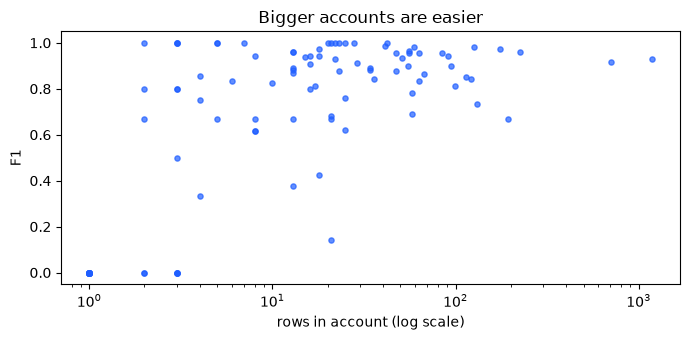

In [23]:
report = pd.DataFrame(classification_report(df["accountName"], final["pred"], output_dict=True, zero_division=0)).T
report = report.drop(index=["accuracy", "macro avg", "weighted avg"]).sort_values("support", ascending=False)
report["support"] = report["support"].astype(int)
print("Largest 15 accounts:")
print(report.head(15).to_string(float_format=lambda x: f"{x:.2f}"))
print("\nWorst F1 among accounts with at least 10 rows:")
print(report[report["support"] >= 10].sort_values("f1-score").head(10).to_string(float_format=lambda x: f"{x:.2f}"))
print(f"\nAccounts with fewer than 5 rows: {(report['support'] < 5).sum()}, "
      f"recall on those rows: {report[report['support'] < 5].eval('recall * support').sum() / report[report['support'] < 5]['support'].sum():.2f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.scatter(report["support"], report["f1-score"], s=14, color="#1f5eff", alpha=0.7)
ax.set_xscale("log")
ax.set_xlabel("rows in account (log scale)")
ax.set_ylabel("F1")
ax.set_title("Bigger accounts are easier")
plt.tight_layout()
plt.savefig("figures/f1_vs_support.png", dpi=130)
plt.show()

### 5c. Confusion matrix for the 15 largest accounts

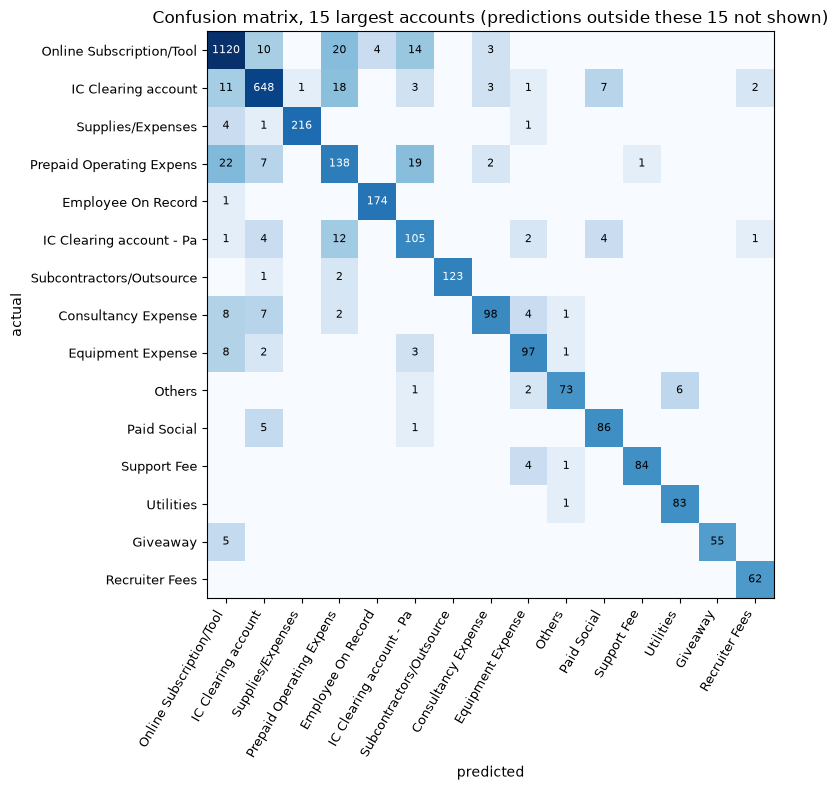

In [24]:
top = counts.head(15).index.tolist()
mask = df["accountName"].isin(top)
cm = confusion_matrix(df.loc[mask, "accountName"], final.loc[mask, "pred"], labels=top)
short = [c.split(" ", 1)[1][:24] for c in top]  # drop the code so labels fit
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(np.log1p(cm), cmap="Blues")
ax.set_xticks(range(len(top)), short, rotation=60, ha="right", fontsize=9)
ax.set_yticks(range(len(top)), short, fontsize=9)
for i in range(len(top)):
    for j in range(len(top)):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 100 else "black")
ax.set_xlabel("predicted")
ax.set_ylabel("actual")
ax.set_title("Confusion matrix, 15 largest accounts (predictions outside these 15 not shown)")
plt.tight_layout()
plt.savefig("figures/confusion_matrix.png", dpi=130)
plt.show()

### 5d. A look at the actual mistakes

In [25]:
errors = df.loc[~correct, ["vendorId", "text", "itemTotalAmount", "accountName"]].copy()
errors["predicted"] = final.loc[~correct, "pred"]
errors["conf"] = final.loc[~correct, "conf"].round(2)
confused_pairs = errors.groupby(["accountName", "predicted"]).size().sort_values(ascending=False)
print("Most common confusions (actual -> predicted):")
print(confused_pairs.head(10).to_string())
print("\nA sample of errors:")
print(errors.sample(12, random_state=SEED).to_string())

Most common confusions (actual -> predicted):
accountName                                  predicted                                  
134001 Prepaid Operating Expense             611202 Online Subscription/Tool                22
611202 Online Subscription/Tool              134001 Prepaid Operating Expense               20
134001 Prepaid Operating Expense             132098 IC Clearing account - Paid on Behalf    19
132098 IC Clearing account                   134001 Prepaid Operating Expense               18
134004 Prepaid Subscription                  134001 Prepaid Operating Expense               17
611202 Online Subscription/Tool              132098 IC Clearing account - Paid on Behalf    14
132098 IC Clearing account - Paid on Behalf  134001 Prepaid Operating Expense               12
619209 Others                                617201 Audit Fee                               12
132098 IC Clearing account                   611202 Online Subscription/Tool                11
611202 Onl

### 5e. Confidence gate: how much could be auto-coded?

In production we would not post every prediction. We would auto-code the confident ones and send
the rest to a reviewer with the top 3 suggestions. The curve below shows the trade-off.

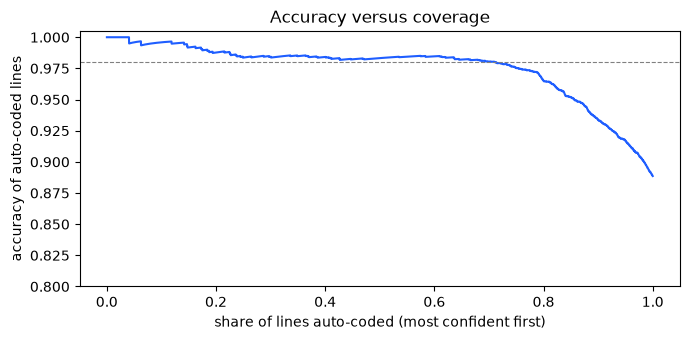

keep auto-coded accuracy >= 99%: auto-code 18% of lines (confidence threshold 0.99), send 82% to review
keep auto-coded accuracy >= 98%: auto-code 71% of lines (confidence threshold 0.95), send 29% to review
keep auto-coded accuracy >= 95%: auto-code 86% of lines (confidence threshold 0.71), send 14% to review

The correct account is in the top 3 suggestions for 95.3% of all lines.


In [26]:
order = np.argsort(-final["conf"].values)
cum_acc = np.cumsum(correct[order]) / np.arange(1, len(order) + 1)
coverage = np.arange(1, len(order) + 1) / len(order)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(coverage, cum_acc, color="#1f5eff")
ax.axhline(0.98, color="grey", ls="--", lw=0.8)
ax.set_xlabel("share of lines auto-coded (most confident first)")
ax.set_ylabel("accuracy of auto-coded lines")
ax.set_title("Accuracy versus coverage")
ax.set_ylim(0.8, 1.005)
plt.tight_layout()
plt.savefig("figures/coverage_curve.png", dpi=130)
plt.show()

for target in [0.99, 0.98, 0.95]:
    ok = np.where(cum_acc >= target)[0]
    cov = coverage[ok[-1]] if len(ok) else 0
    thr = final["conf"].values[order][ok[-1]] if len(ok) else 1
    print(f"keep auto-coded accuracy >= {target:.0%}: auto-code {cov:.0%} of lines (confidence threshold {thr:.2f}), "
          f"send {1 - cov:.0%} to review")

top3_of_reviewed = np.mean([t in row for t, row in zip(df["accountName"], final["top3"])])
print(f"\nThe correct account is in the top 3 suggestions for {top3_of_reviewed:.1%} of all lines.")

## 6. Summary

The numbers above feed the written report in `docs/report.md`. In short: a memory lookup plus one
logistic regression, validated without leakage, clears the 85% bar on grouped cross-validation.
The time split is lower, because of an account rename right after the cutoff and because of
vendors and wording the model has never seen. That is the honest number to plan a deployment around.

In [27]:
summary = pd.DataFrame({"grouped 5-fold CV": ladder["+ months covered, lines in bill (final)"],
                        "time split (Sep 2025 to Feb 2026)": time_summary}).T
print(summary.to_string(float_format=lambda x: f"{x:.3f}"))
summary.to_csv("figures/summary.csv")

                                   accuracy  macro_f1  weighted_f1  top3_accuracy  memory_share
grouped 5-fold CV                     0.889     0.664        0.884          0.953         0.473
time split (Sep 2025 to Feb 2026)     0.704     0.584        0.674          0.779         0.390
